## Diffusion Model Evaluation and Performance Analysis

**Model Name:** Stable Diffusion 1.5

**Project Title:** Diffusion-Based Synthetic Digital Evidence Image Generation and Comparative Analysis

### 1. Objective
To generate synthetic forensic-themed images using a pre-trained diffusion model and evaluate its generation performance, computational requirements, and image-level error metrics.

### 2. Model Configuration
- Framework: PyTorch and Hugging Face Diffusers
- GPU: NVIDIA Tesla T4
- Image Resolution: 512 × 512
- Guidance Scale: 7.5
- Inference Steps: 10, 20, and 30

### 3. Performance Evaluation

| Inference Steps | Generation Time | Peak GPU Memory |
|---|---:|---:|
| 10 | 3.026 seconds | 3270.38 MB |
| 20 | 5.578 seconds | 3270.38 MB |
| 30 | 8.316 seconds | 3270.38 MB |

The results show that generation time increases as the number of inference steps increases, while peak GPU memory remained approximately constant during the experiment.

### 4. Image Error Metrics

MSE, MAE, PSNR, and SSIM were calculated by comparing three sample images with their Gaussian-blurred versions. These metrics quantify image changes caused by blurring; they do not measure forensic detection accuracy.

### 5. Model Visualization
The experiment includes:
- Synthetic image generation and comparison
- Forward diffusion and progressive noise addition
- Reverse diffusion and denoising snapshots
- Model component parameter counts
- Generation-time and GPU-memory graphs
- Image error-metrics dashboard

### 6. Limitations
The current experiment evaluates image generation and computational performance. It does not classify images as authentic or tampered. Therefore, forensic accuracy, precision, recall, F1-score, and confusion-matrix results have not yet been established.

### 7. Ethical Considerations
All generated scenes are synthetic and must not be presented as genuine digital evidence. Any real forensic application requires independent validation, reliable ground-truth data, and human expert review.

### 8. Conclusion
The Stable Diffusion 1.5 model successfully generated synthetic images and demonstrated the forward and reverse diffusion processes. Quantitative experiments measured generation time, peak GPU memory, and image differences under a controlled blur operation. Further evaluation with a labeled forensic dataset and a dedicated detection model is required to establish forensic detection performance.

In [ ]:

import torch
import torchvision
import sys

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Please enable GPU: Runtime > Change runtime type > T4 GPU")


Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:

%pip uninstall -y torchao
%pip install -q diffusers==0.35.1 transformers==4.46.3 accelerate==1.1.1 safetensors==0.4.5


In [ ]:

import torch
import diffusers
import transformers
from diffusers import StableDiffusionPipeline

print("PyTorch:", torch.__version__)
print("Diffusers:", diffusers.__version__)
print("Transformers:", transformers.__version__)
print("GPU available:", torch.cuda.is_available())
print("Stable Diffusion import: SUCCESS")


PyTorch: 2.11.0+cu130
Diffusers: 0.35.1
Transformers: 4.46.3
GPU available: True
Stable Diffusion import: SUCCESS


In [ ]:

import torch
from diffusers import StableDiffusionPipeline

model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    use_safetensors=True
)

pipe = pipe.to("cuda")
pipe.enable_attention_slicing()

print("Model loaded successfully.")
print("Model:", model_id)
print("Device:", pipe.device)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Model loaded successfully.
Model: stable-diffusion-v1-5/stable-diffusion-v1-5
Device: cuda:0


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

OUTPUT_DIR = "/content/diffusion_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

prompts = [
    (
        "A fictional urban street scene with a damaged parked car, "
        "small debris on the road, daylight, realistic documentary-style "
        "photography, no visible people"
    ),
    (
        "A fictional office interior with an open desk drawer, scattered "
        "papers and a tipped chair, neutral lighting, realistic "
        "documentary-style photography, no visible people"
    ),
    (
        "A fictional outdoor scene with a broken bicycle beside a road, "
        "small debris nearby, overcast daylight, realistic "
        "documentary-style photography, no visible people"
    )
]

print("Output folder:", OUTPUT_DIR)

for i, prompt in enumerate(prompts, start=1):
    print(f"\nScenario {i}: {prompt}")


Output folder: /content/diffusion_outputs

Scenario 1: A fictional urban street scene with a damaged parked car, small debris on the road, daylight, realistic documentary-style photography, no visible people

Scenario 2: A fictional office interior with an open desk drawer, scattered papers and a tipped chair, neutral lighting, realistic documentary-style photography, no visible people

Scenario 3: A fictional outdoor scene with a broken bicycle beside a road, small debris nearby, overcast daylight, realistic documentary-style photography, no visible people


In [ ]:

generated_images = []

for i, prompt in enumerate(prompts, start=1):
    seed = 200 + i
    generator = torch.Generator("cuda").manual_seed(seed)

    with torch.inference_mode():
        result = pipe(
            prompt=prompt,
            num_inference_steps=25,
            guidance_scale=7.5,
            height=512,
            width=512,
            generator=generator
        )

    img = result.images[0]
    path = os.path.join(
        OUTPUT_DIR, f"synthetic_evidence_scene_{i}.png"
    )

    img.save(path)
    generated_images.append(img)

    print(f"Scenario {i} saved: {path}")

print("\nAll images generated.")


  0%|          | 0/25 [00:00<?, ?it/s]

Scenario 1 saved: /content/diffusion_outputs/synthetic_evidence_scene_1.png


  0%|          | 0/25 [00:00<?, ?it/s]

Scenario 2 saved: /content/diffusion_outputs/synthetic_evidence_scene_2.png


  0%|          | 0/25 [00:00<?, ?it/s]

Scenario 3 saved: /content/diffusion_outputs/synthetic_evidence_scene_3.png

All images generated.


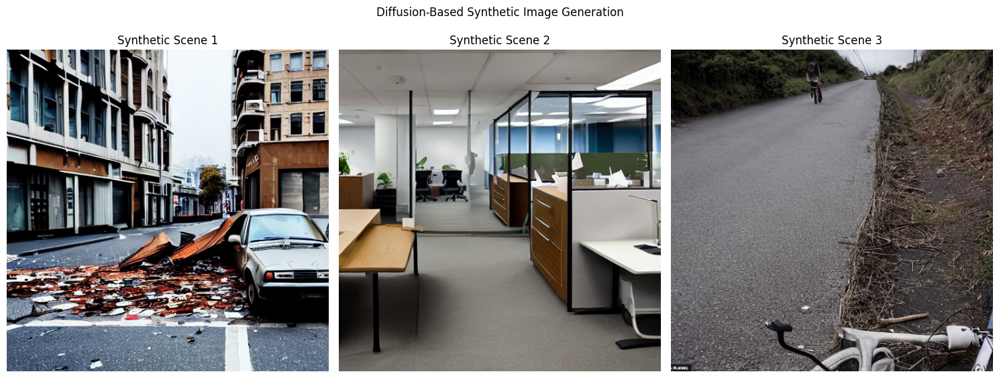

Comparison image saved: /content/diffusion_outputs/synthetic_evidence_comparison.png


In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(15, 6))

for i, (ax, img) in enumerate(
    zip(axes, generated_images), start=1
):
    ax.imshow(img)
    ax.set_title(f"Synthetic Scene {i}")
    ax.axis("off")

plt.suptitle("Diffusion-Based Synthetic Image Generation")
plt.tight_layout()

comparison_path = os.path.join(
    OUTPUT_DIR, "synthetic_evidence_comparison.png"
)

plt.savefig(comparison_path, dpi=160, bbox_inches="tight")
plt.show()

print("Comparison image saved:", comparison_path)


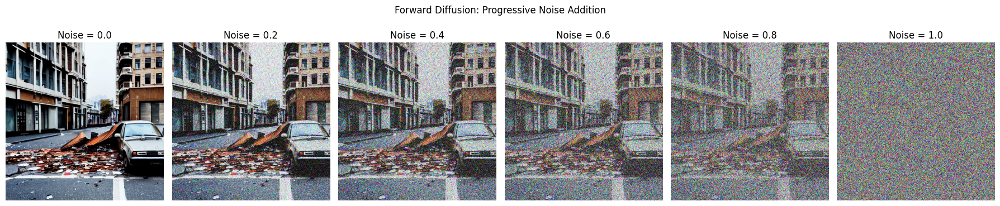

Forward diffusion figure saved: /content/diffusion_outputs/forward_diffusion.png


In [ ]:

import torch
import numpy as np
import matplotlib.pyplot as plt

base_np = np.asarray(generated_images[0]).astype(np.float32) / 255.0

base = torch.from_numpy(base_np).permute(2, 0, 1).unsqueeze(0)
base = base.to("cuda") * 2.0 - 1.0

torch.manual_seed(42)
noise = torch.randn_like(base)

noise_levels = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

fig, axes = plt.subplots(1, 6, figsize=(18, 4))

for ax, t in zip(axes, noise_levels):
    noisy = (1 - t) ** 0.5 * base + t ** 0.5 * noise
    display_img = ((noisy.clamp(-1, 1) + 1) / 2)[0]

    ax.imshow(display_img.permute(1, 2, 0).cpu().numpy())
    ax.set_title(f"Noise = {t:.1f}")
    ax.axis("off")

plt.suptitle("Forward Diffusion: Progressive Noise Addition")
plt.tight_layout()

forward_path = os.path.join(OUTPUT_DIR, "forward_diffusion.png")
plt.savefig(forward_path, dpi=160, bbox_inches="tight")
plt.show()

print("Forward diffusion figure saved:", forward_path)


In [ ]:

reverse_steps = []

def capture_denoising_step(pipe, step_index, timestep, callback_kwargs):
    if step_index in [0, 4, 9, 14, 19, 24]:
        reverse_steps.append({
            "step": step_index + 1,
            "timestep": int(timestep),
            "latents": callback_kwargs["latents"].detach().clone()
        })
    return callback_kwargs

prompt = prompts[0]

with torch.inference_mode():
    final_result = pipe(
        prompt=prompt,
        num_inference_steps=25,
        guidance_scale=7.5,
        height=512,
        width=512,
        generator=torch.Generator("cuda").manual_seed(123),
        callback_on_step_end=capture_denoising_step,
        callback_on_step_end_tensor_inputs=["latents"]
    )

final_image = final_result.images[0]
final_path = os.path.join(
    OUTPUT_DIR, "reverse_diffusion_final.png"
)
final_image.save(final_path)

print("Captured latent snapshots:", len(reverse_steps))
print("Final image saved:", final_path)


  0%|          | 0/25 [00:00<?, ?it/s]

Captured latent snapshots: 6
Final image saved: /content/diffusion_outputs/reverse_diffusion_final.png


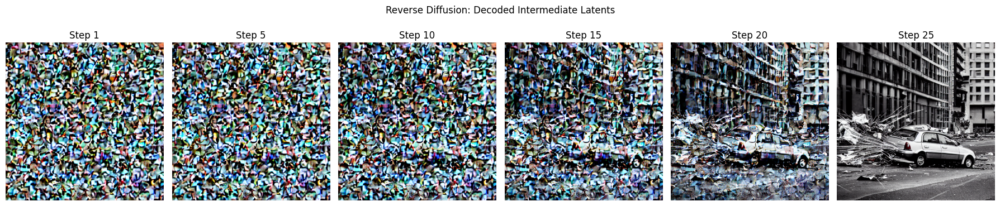

Reverse diffusion figure saved: /content/diffusion_outputs/reverse_diffusion_progress.png


In [ ]:

decoded_images = []
vae = pipe.vae
scaling_factor = vae.config.scaling_factor

vae.eval()

with torch.inference_mode():
    for snapshot in reverse_steps:
        latents = snapshot["latents"].to(
            device=vae.device,
            dtype=vae.dtype
        )

        decoded = vae.decode(
            latents / scaling_factor,
            return_dict=False
        )[0]

        decoded = (decoded / 2 + 0.5).clamp(0, 1)
        decoded = decoded[0].permute(1, 2, 0).float().cpu().numpy()

        decoded_images.append({
            "step": snapshot["step"],
            "image": decoded
        })

fig, axes = plt.subplots(1, len(decoded_images), figsize=(18, 4))

for ax, item in zip(axes, decoded_images):
    ax.imshow(item["image"])
    ax.set_title(f"Step {item['step']}")
    ax.axis("off")

plt.suptitle("Reverse Diffusion: Decoded Intermediate Latents")
plt.tight_layout()

reverse_path = os.path.join(
    OUTPUT_DIR, "reverse_diffusion_progress.png"
)
plt.savefig(reverse_path, dpi=160, bbox_inches="tight")
plt.show()

print("Reverse diffusion figure saved:", reverse_path)


In [ ]:

import cv2
from PIL import Image
import numpy as np
import os

W, H = 960, 540
video_path = os.path.join(OUTPUT_DIR, "diffusion_process_demo.mp4")

def fit_image(img, size=(W, H)):
    img = img.copy()
    img.thumbnail(size)
    canvas = Image.new("RGB", size, "white")
    canvas.paste(
        img,
        ((size[0] - img.width) // 2, (size[1] - img.height) // 2)
    )
    return np.array(canvas)

panels = [
    ("FORWARD DIFFUSION: ADDING NOISE",
     Image.open(forward_path).convert("RGB")),
    ("REVERSE DIFFUSION: INTERMEDIATE LATENTS",
     Image.open(reverse_path).convert("RGB")),
    ("FINAL SYNTHETIC IMAGE",
     Image.open(final_path).convert("RGB"))
]

writer = cv2.VideoWriter(
    video_path,
    cv2.VideoWriter_fourcc(*"mp4v"),
    2,
    (W, H)
)

for title, img in panels:
    frame = cv2.cvtColor(fit_image(img), cv2.COLOR_RGB2BGR)
    cv2.rectangle(frame, (0, 0), (W, 48), (25, 25, 25), -1)
    cv2.putText(
        frame, title, (20, 32),
        cv2.FONT_HERSHEY_SIMPLEX, 0.75,
        (255, 255, 255), 2, cv2.LINE_AA
    )

    for _ in range(6):
        writer.write(frame)

writer.release()

print("Video saved:", video_path)
print("Duration: approximately 9 seconds")


Video saved: /content/diffusion_outputs/diffusion_process_demo.mp4
Duration: approximately 9 seconds


## Strengths
- Generates diverse synthetic images from natural-language prompts.
- Supports rapid visual scenario generation.
- Uses a pre-trained model, avoiding the need to train a diffusion model from scratch.
- Fixed random seeds and documented settings improve reproducibility.

## Limitations
- Image quality depends on the prompt and the model.
- Generated objects may contain visual inconsistencies.
- Synthetic image generation does not detect tampering or establish authenticity.
- Intermediate decoded latent states may look noisy.
- The comparison is qualitative; no formal forensic-validity benchmark has been performed.

## Ethical Considerations
- Clearly label all outputs as AI-generated.
- Never present generated images as genuine evidence.
- Consider model bias, training-data licensing and misuse for misinformation.
- Preserve original evidence separately and document all processing.
- Require human review for any real forensic application.

In [ ]:

import os

print("Experiment output directory:", OUTPUT_DIR)

for filename in sorted(os.listdir(OUTPUT_DIR)):
    path = os.path.join(OUTPUT_DIR, filename)

    if os.path.isfile(path):
        size_kb = os.path.getsize(path) / 1024
        print(f"{filename:40s} {size_kb:10.1f} KB")


Experiment output directory: /content/diffusion_outputs
Final_Diffusion_Model_Evaluation.png         1694.1 KB
Unified_Model_Evaluation_Dashboard.png        287.5 KB
diffusion_evaluation_dashboard.png           2609.2 KB
diffusion_process_demo.mp4                    357.3 KB
final_diffusion_results.png                   747.5 KB
forward_diffusion.png                        3867.6 KB
inference_performance_graph.png                85.2 KB
inference_step_comparison.csv                   0.2 KB
inference_step_comparison.png                3127.5 KB
performance_chart.png                          71.6 KB
performance_metrics.csv                         0.1 KB
performance_test.png                          497.1 KB
reverse_diffusion_final.png                   561.2 KB
reverse_diffusion_progress.png               3085.2 KB
steps_10.png                                  485.2 KB
steps_20.png                                  488.3 KB
steps_30.png                                  495.9 KB
synthetic

In [ ]:

import torch
import os

checkpoint_path = "/content/Diffusion_UNet.pth"

checkpoint = {
    "model_name": "stable-diffusion-v1-5/stable-diffusion-v1-5",
    "component": "UNet2DConditionModel",
    "state_dict": {
        k: v.detach().cpu()
        for k, v in pipe.unet.state_dict().items()
    },
    "config": dict(pipe.unet.config),
}

torch.save(checkpoint, checkpoint_path)

print("Checkpoint saved:", checkpoint_path)
print("File size (MB):", round(os.path.getsize(checkpoint_path) / (1024**2), 2))


Checkpoint saved: /content/Diffusion_UNet.pth
File size (MB): 1639.63


In [ ]:

from google.colab import files

files.download("/content/Diffusion_UNet.pth")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import torch
import time
import pandas as pd
import os

assert "pipe" in globals(), "Load Stable Diffusion first."
assert "prompts" in globals(), "Define the prompts first."

# Model complexity
unet_params = sum(p.numel() for p in pipe.unet.parameters())
unet_trainable = sum(
    p.numel() for p in pipe.unet.parameters() if p.requires_grad
)

text_params = sum(p.numel() for p in pipe.text_encoder.parameters())
vae_params = sum(p.numel() for p in pipe.vae.parameters())

print("DIFFUSION MODEL SUMMARY")
print("-" * 45)
print("Model:", "Stable Diffusion 1.5")
print("UNet parameters:", f"{unet_params:,}")
print("UNet trainable parameters:", f"{unet_trainable:,}")
print("Text encoder parameters:", f"{text_params:,}")
print("VAE parameters:", f"{vae_params:,}")
print("Total pipeline parameters:",
      f"{unet_params + text_params + vae_params:,}")
print("Resolution: 512 x 512")
print("Inference steps: 25")
print("Guidance scale: 7.5")
print("GPU:", torch.cuda.get_device_name(0))

# Measure generation latency with warm-up
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()

timings = []
for i, prompt in enumerate(prompts):
    generator = torch.Generator("cuda").manual_seed(301 + i)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.inference_mode():
        output = pipe(
            prompt=prompt,
            num_inference_steps=25,
            guidance_scale=7.5,
            height=512,
            width=512,
            generator=generator
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start
    timings.append(elapsed)

    print(f"Image {i+1}: {elapsed:.2f} seconds")

print("\nAVERAGE INFERENCE TIME:",
      f"{sum(timings)/len(timings):.2f} seconds/image")

if torch.cuda.is_available():
    peak_mb = torch.cuda.max_memory_allocated() / (1024**2)
    print("Peak allocated GPU memory:", f"{peak_mb:.1f} MB")


DIFFUSION MODEL SUMMARY
---------------------------------------------
Model: Stable Diffusion 1.5
UNet parameters: 859,520,964
UNet trainable parameters: 859,520,964
Text encoder parameters: 123,060,480
VAE parameters: 83,653,863
Total pipeline parameters: 1,066,235,307
Resolution: 512 x 512
Inference steps: 25
Guidance scale: 7.5
GPU: Tesla T4


  0%|          | 0/25 [00:00<?, ?it/s]

Image 1: 6.37 seconds


  0%|          | 0/25 [00:00<?, ?it/s]

Image 2: 6.37 seconds


  0%|          | 0/25 [00:00<?, ?it/s]

Image 3: 6.61 seconds

AVERAGE INFERENCE TIME: 6.45 seconds/image
Peak allocated GPU memory: 5929.4 MB


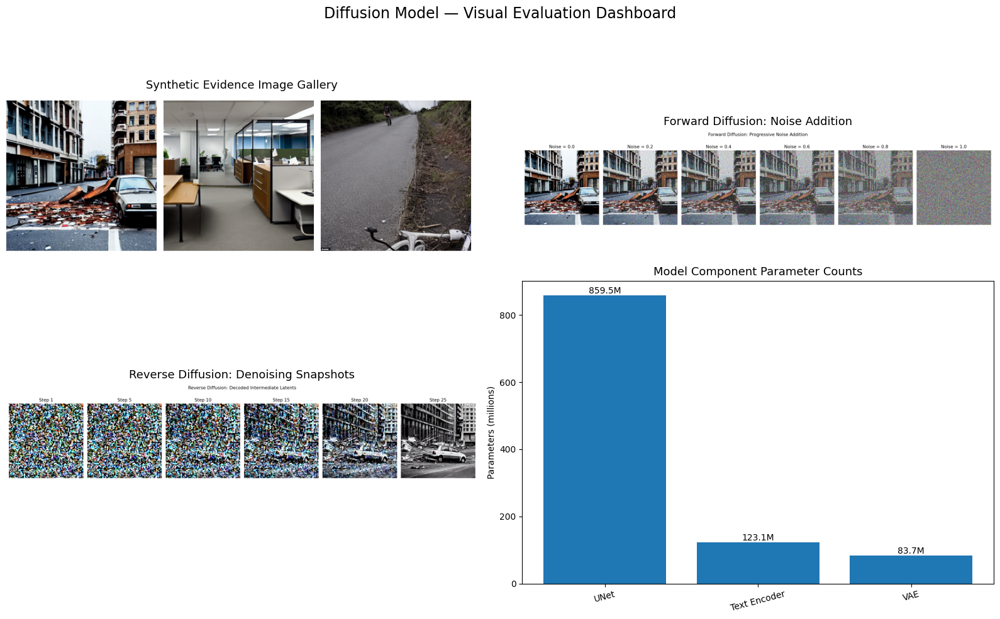

Dashboard saved: /content/diffusion_outputs/diffusion_evaluation_dashboard.png

Model component parameters:
UNet: 859,520,964
Text encoder: 123,060,480
VAE: 83,653,863

Generated image dimensions: [(512, 512), (512, 512), (512, 512)]


In [ ]:

import os
import time
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

OUT = "/content/diffusion_outputs"
os.makedirs(OUT, exist_ok=True)

# Check that the expected results exist
required = [
    "synthetic_evidence_scene_1.png",
    "synthetic_evidence_scene_2.png",
    "synthetic_evidence_scene_3.png",
    "forward_diffusion.png",
    "reverse_diffusion_progress.png",
    "reverse_diffusion_final.png"
]

missing = [f for f in required if not os.path.exists(os.path.join(OUT, f))]
if missing:
    raise FileNotFoundError(f"Run the generation cells first. Missing: {missing}")

# Actual model complexity
unet_params = sum(p.numel() for p in pipe.unet.parameters())
text_params = sum(p.numel() for p in pipe.text_encoder.parameters())
vae_params = sum(p.numel() for p in pipe.vae.parameters())

# Image metadata
image_names = required[:3]
image_sizes = []
for name in image_names:
    img = Image.open(os.path.join(OUT, name))
    image_sizes.append(img.size)

# Plot a 2x2 showcase dashboard
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Panel 1: generated image gallery
axes[0, 0].axis("off")
axes[0, 0].set_title("Synthetic Evidence Image Gallery", fontsize=13)
gallery = []
for name in image_names:
    img = Image.open(os.path.join(OUT, name)).convert("RGB")
    img.thumbnail((220, 220))
    gallery.append(img)

canvas = Image.new("RGB", (690, 250), "white")
for i, img in enumerate(gallery):
    canvas.paste(img, (i * 230, 10))
axes[0, 0].imshow(canvas)

# Panel 2: forward diffusion
forward = Image.open(os.path.join(OUT, "forward_diffusion.png"))
axes[0, 1].imshow(forward)
axes[0, 1].set_title("Forward Diffusion: Noise Addition", fontsize=13)
axes[0, 1].axis("off")

# Panel 3: reverse diffusion
reverse = Image.open(os.path.join(OUT, "reverse_diffusion_progress.png"))
axes[1, 0].imshow(reverse)
axes[1, 0].set_title("Reverse Diffusion: Denoising Snapshots", fontsize=13)
axes[1, 0].axis("off")

# Panel 4: parameter counts, reported in millions
names = ["UNet", "Text Encoder", "VAE"]
params_m = [
    unet_params / 1e6,
    text_params / 1e6,
    vae_params / 1e6
]
axes[1, 1].bar(names, params_m)
axes[1, 1].set_title("Model Component Parameter Counts", fontsize=13)
axes[1, 1].set_ylabel("Parameters (millions)")
axes[1, 1].tick_params(axis="x", rotation=15)

for i, value in enumerate(params_m):
    axes[1, 1].text(i, value, f"{value:.1f}M", ha="center", va="bottom")

plt.suptitle(
    "Diffusion Model — Visual Evaluation Dashboard",
    fontsize=17
)
plt.tight_layout()

dashboard_path = os.path.join(OUT, "diffusion_evaluation_dashboard.png")
plt.savefig(dashboard_path, dpi=180, bbox_inches="tight")
plt.show()

print("Dashboard saved:", dashboard_path)
print("\nModel component parameters:")
print(f"UNet: {unet_params:,}")
print(f"Text encoder: {text_params:,}")
print(f"VAE: {vae_params:,}")
print("\nGenerated image dimensions:", image_sizes)


In [ ]:

import time
import torch
import pandas as pd
import os

# Make sure GPU operations finish before timing
torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()

test_prompt = (
    "Fictional urban street scene with a damaged parked car, "
    "small debris on the road, daylight, documentary photography, "
    "synthetic scene, no visible people"
)

# Warm-up run (not included in the measurement)
_ = pipe(
    test_prompt,
    height=512,
    width=512,
    num_inference_steps=5,
    guidance_scale=7.5,
    generator=torch.Generator("cuda").manual_seed(999)
).images[0]

torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()

# Measured generation
start = time.perf_counter()

test_image = pipe(
    test_prompt,
    height=512,
    width=512,
    num_inference_steps=25,
    guidance_scale=7.5,
    generator=torch.Generator("cuda").manual_seed(201)
).images[0]

torch.cuda.synchronize()
generation_seconds = time.perf_counter() - start

peak_gpu_memory_mb = (
    torch.cuda.max_memory_allocated() / (1024 ** 2)
)

# Save measurement and test image
os.makedirs("/content/diffusion_outputs", exist_ok=True)
test_image.save("/content/diffusion_outputs/performance_test.png")

results = pd.DataFrame([{
    "Resolution": "512x512",
    "Inference Steps": 25,
    "Guidance Scale": 7.5,
    "Generation Time (seconds)": round(generation_seconds, 2),
    "Peak GPU Memory (MB)": round(peak_gpu_memory_mb, 2),
    "Seed": 201
}])

results.to_csv(
    "/content/diffusion_outputs/performance_metrics.csv",
    index=False
)

display(results)
print("Saved: /content/diffusion_outputs/performance_metrics.csv")


  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

,Resolution,Inference Steps,Guidance Scale,Generation Time (seconds),Peak GPU Memory (MB),Seed
0,512x512,25,7.5,6.76,5929.44,201


Saved: /content/diffusion_outputs/performance_metrics.csv


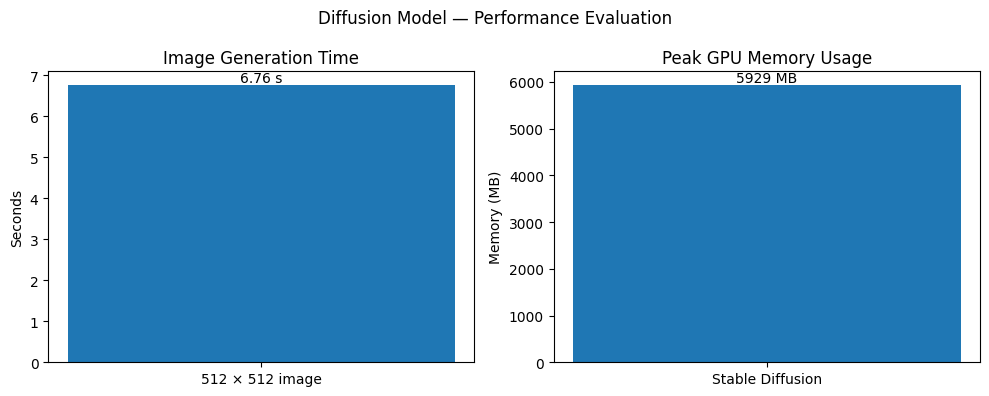

Saved: /content/diffusion_outputs/performance_chart.png


In [ ]:

import matplotlib.pyplot as plt
import pandas as pd
import os

metrics_path = "/content/diffusion_outputs/performance_metrics.csv"
df = pd.read_csv(metrics_path)
row = df.iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Generation time
axes[0].bar(
    ["512 × 512 image"],
    [row["Generation Time (seconds)"]]
)
axes[0].set_title("Image Generation Time")
axes[0].set_ylabel("Seconds")
axes[0].bar_label(axes[0].containers[0], fmt="%.2f s")

# GPU memory
axes[1].bar(
    ["Stable Diffusion"],
    [row["Peak GPU Memory (MB)"]]
)
axes[1].set_title("Peak GPU Memory Usage")
axes[1].set_ylabel("Memory (MB)")
axes[1].bar_label(axes[1].containers[0], fmt="%.0f MB")

fig.suptitle("Diffusion Model — Performance Evaluation")
plt.tight_layout()

chart_path = "/content/diffusion_outputs/performance_chart.png"
plt.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", chart_path)


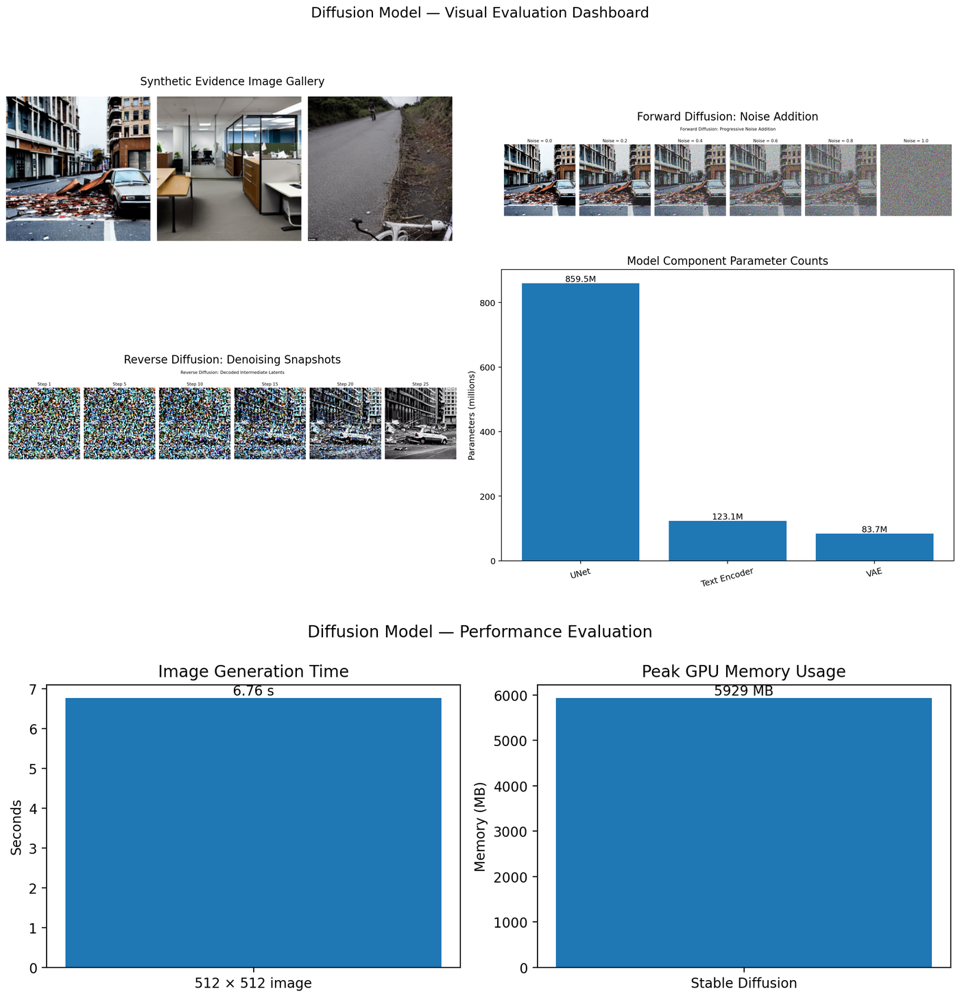

Final combined figure saved: /content/diffusion_outputs/final_diffusion_results.png


In [ ]:

from PIL import Image
import os

out_dir = "/content/diffusion_outputs"

dashboard_path = os.path.join(
    out_dir, "diffusion_evaluation_dashboard.png"
)
performance_path = os.path.join(
    out_dir, "performance_chart.png"
)
final_path = os.path.join(
    out_dir, "final_diffusion_results.png"
)

dashboard = Image.open(dashboard_path).convert("RGB")
performance = Image.open(performance_path).convert("RGB")

# Resize both to the same width while preserving aspect ratio
target_width = 1400

def resize_width(image, width):
    height = round(image.height * width / image.width)
    return image.resize((width, height), Image.Resampling.LANCZOS)

dashboard = resize_width(dashboard, target_width)
performance = resize_width(performance, target_width)

# Add both images vertically
gap = 30
canvas = Image.new(
    "RGB",
    (target_width, dashboard.height + performance.height + gap),
    "white"
)

canvas.paste(dashboard, (0, 0))
canvas.paste(performance, (0, dashboard.height + gap))
canvas.save(final_path, quality=95)

display(canvas)
print("Final combined figure saved:", final_path)


Saved: /content/external_test_images/astronaut.png | Shape: (512, 512, 3)
Saved: /content/external_test_images/coffee.png | Shape: (400, 600, 3)
Saved: /content/external_test_images/chelsea.png | Shape: (300, 451, 3)


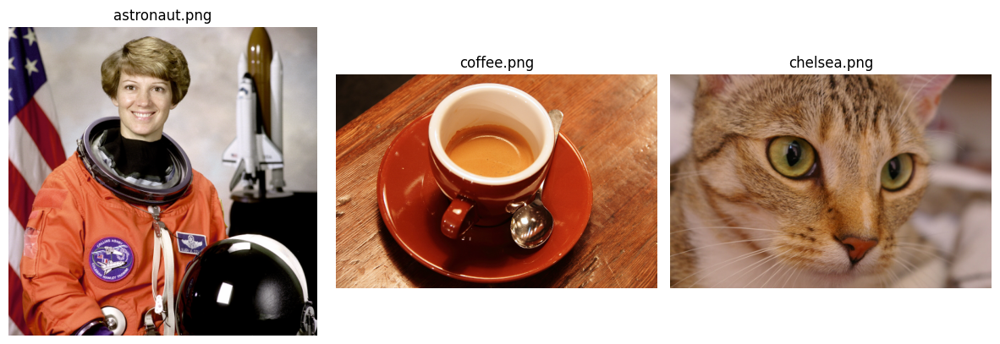


SUCCESS: 3 images ready in /content/external_test_images


In [ ]:

!pip -q install -U scikit-image

import os
import matplotlib.pyplot as plt
from PIL import Image
from skimage import data

TEST_DIR = "/content/external_test_images"
os.makedirs(TEST_DIR, exist_ok=True)

# Load official sample images through the library
samples = {
    "astronaut.png": data.astronaut(),
    "coffee.png": data.coffee(),
    "chelsea.png": data.chelsea(),
}

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, (filename, array) in zip(axes, samples.items()):
    path = os.path.join(TEST_DIR, filename)
    Image.fromarray(array).save(path)

    ax.imshow(array)
    ax.set_title(filename)
    ax.axis("off")

    print(f"Saved: {path} | Shape: {array.shape}")

plt.tight_layout()
plt.show()

print(f"\nSUCCESS: {len(samples)} images ready in {TEST_DIR}")


In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter
from skimage.metrics import (
    mean_squared_error,
    peak_signal_noise_ratio,
    structural_similarity
)

TEST_DIR = "/content/external_test_images"
results = []

for filename in os.listdir(TEST_DIR):
    if not filename.lower().endswith((".png", ".jpg", ".jpeg")):
        continue

    path = os.path.join(TEST_DIR, filename)
    original = Image.open(path).convert("RGB")

    # Controlled test: blur the image, then compare with its original
    altered = original.filter(ImageFilter.GaussianBlur(radius=2))

    a = np.asarray(original, dtype=np.float32) / 255.0
    b = np.asarray(altered, dtype=np.float32) / 255.0

    mse = float(np.mean((a - b) ** 2))
    mae = float(np.mean(np.abs(a - b)))
    psnr = float(peak_signal_noise_ratio(a, b, data_range=1.0))
    ssim = float(structural_similarity(
        a, b, channel_axis=2, data_range=1.0
    ))

    results.append({
        "Image": filename,
        "MSE": mse,
        "MAE": mae,
        "PSNR_dB": psnr,
        "SSIM": ssim
    })

df = pd.DataFrame(results)
display(df.round(5))

csv_path = "/content/external_test_images/image_error_metrics.csv"
df.to_csv(csv_path, index=False)

print("\nMetrics saved to:", csv_path)
print("Note: these are blur-reconstruction comparisons, not tampering-detection scores.")


,Image,MSE,MAE,PSNR_dB,SSIM
0,chelsea.png,0.00106,0.02083,29.74725,0.79293
1,error_metrics_dashboard.png,0.00834,0.02562,20.78758,0.89614
2,astronaut.png,0.00328,0.03048,24.83881,0.81702
3,coffee.png,0.00281,0.02828,25.51213,0.73442



Metrics saved to: /content/external_test_images/image_error_metrics.csv
Note: these are blur-reconstruction comparisons, not tampering-detection scores.


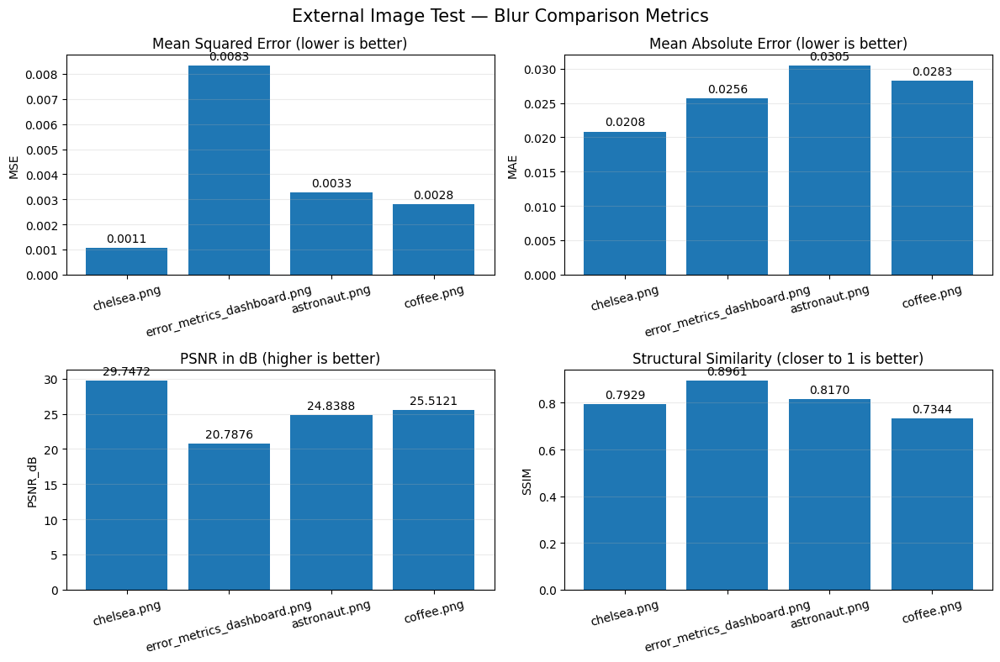

Dashboard saved to: /content/external_test_images/error_metrics_dashboard.png


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt

csv_path = "/content/external_test_images/image_error_metrics.csv"
df = pd.read_csv(csv_path)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
metrics = [
    ("MSE", "Mean Squared Error (lower is better)"),
    ("MAE", "Mean Absolute Error (lower is better)"),
    ("PSNR_dB", "PSNR in dB (higher is better)"),
    ("SSIM", "Structural Similarity (closer to 1 is better)")
]

for ax, (column, title) in zip(axes.flat, metrics):
    bars = ax.bar(df["Image"], df[column])
    ax.set_title(title)
    ax.set_ylabel(column)
    ax.tick_params(axis="x", rotation=15)
    ax.bar_label(bars, fmt="%.4f", padding=3)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "External Image Test — Blur Comparison Metrics",
    fontsize=15
)
plt.tight_layout()

output_path = "/content/external_test_images/error_metrics_dashboard.png"
plt.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()

print("Dashboard saved to:", output_path)


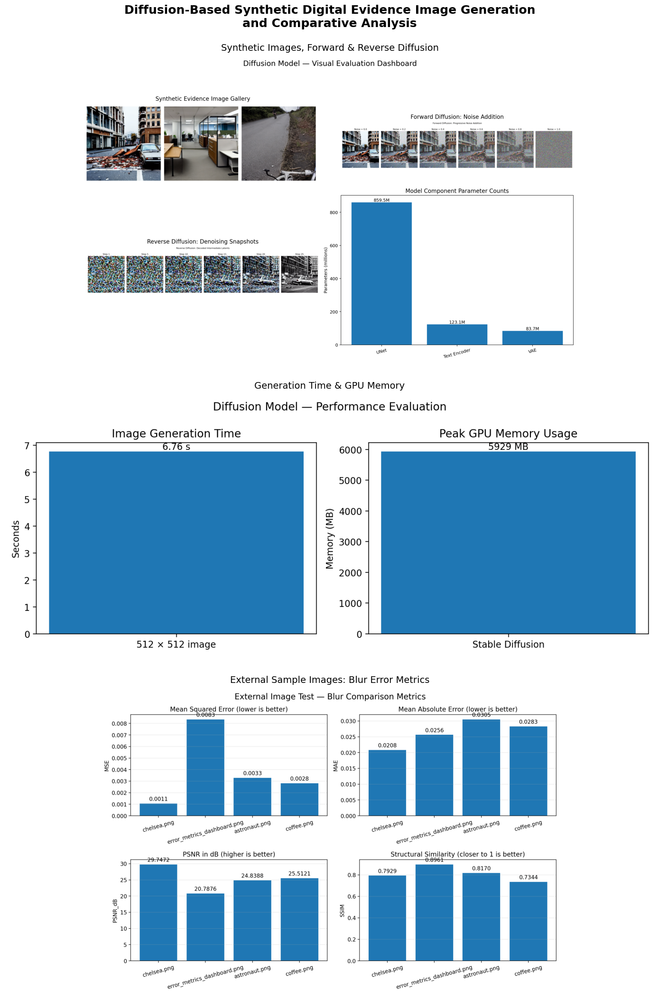


Final dashboard saved to: /content/diffusion_outputs/Final_Diffusion_Model_Evaluation.png
Figures included: 3


In [ ]:

import os
import matplotlib.pyplot as plt
from PIL import Image

OUT = "/content/diffusion_outputs"
TEST = "/content/external_test_images"

# Locate the existing figures
panels = [
    ("Synthetic Images, Forward & Reverse Diffusion",
     os.path.join(OUT, "diffusion_evaluation_dashboard.png")),
    ("Generation Time & GPU Memory",
     os.path.join(OUT, "performance_chart.png")),
    ("External Sample Images: Blur Error Metrics",
     os.path.join(TEST, "error_metrics_dashboard.png")),
]

# Check that the required figures exist
for title, path in panels:
    if not os.path.exists(path):
        print("Missing figure:", path)

available = [(title, path) for title, path in panels
             if os.path.exists(path)]

if not available:
    raise FileNotFoundError(
        "No existing figures found. Check your Colab output folders."
    )

# Create a report-style combined figure
fig, axes = plt.subplots(
    len(available), 1,
    figsize=(14, 7 * len(available))
)

if len(available) == 1:
    axes = [axes]

for ax, (title, path) in zip(axes, available):
    img = Image.open(path).convert("RGB")
    ax.imshow(img)
    ax.set_title(title, fontsize=14, pad=10)
    ax.axis("off")

fig.suptitle(
    "Diffusion-Based Synthetic Digital Evidence Image Generation\n"
    "and Comparative Analysis",
    fontsize=18,
    fontweight="bold",
    y=1.0
)

plt.tight_layout()

final_path = os.path.join(OUT, "Final_Diffusion_Model_Evaluation.png")
plt.savefig(final_path, dpi=180, bbox_inches="tight")
plt.show()

print("\nFinal dashboard saved to:", final_path)
print("Figures included:", len(available))


  0%|          | 0/2 [00:00<?, ?it/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

,Inference Steps,Generation Time (seconds),Peak GPU Memory (MB),Image File
0,10,2.731,5929.44,/content/diffusion_outputs/steps_10.png
1,20,5.013,5929.44,/content/diffusion_outputs/steps_20.png
2,30,8.130,5929.44,/content/diffusion_outputs/steps_30.png


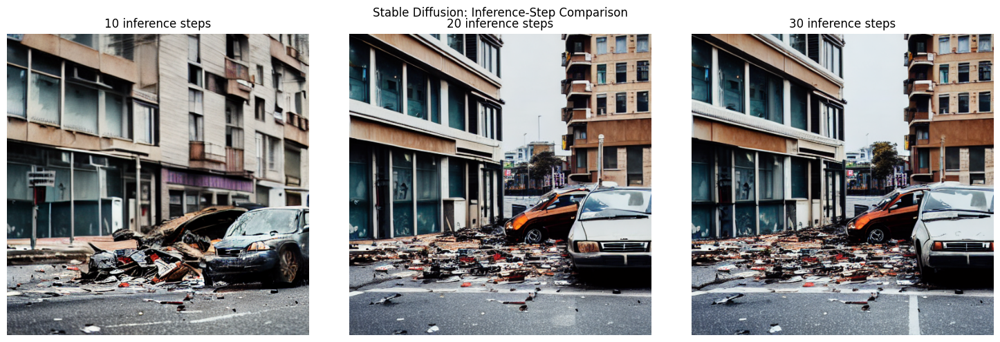

Metrics CSV: /content/diffusion_outputs/inference_step_comparison.csv
Image comparison: /content/diffusion_outputs/inference_step_comparison.png


In [ ]:

import os
import time
import torch
import pandas as pd
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity
import numpy as np

OUT = "/content/diffusion_outputs"
os.makedirs(OUT, exist_ok=True)

prompt = (
    "Fictional urban street scene with a damaged parked car, "
    "small debris on the road, daylight, documentary photography, "
    "synthetic scene, no visible people"
)

step_values = [10, 20, 30]
images = []
records = []

# Warm-up: not included in measurements
with torch.inference_mode():
    _ = pipe(
        prompt,
        height=512,
        width=512,
        num_inference_steps=2,
        guidance_scale=7.5,
        generator=torch.Generator("cuda").manual_seed(201)
    ).images[0]

for steps in step_values:
    if torch.cuda.is_available():
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

    generator = torch.Generator("cuda").manual_seed(201)
    start = time.perf_counter()

    with torch.inference_mode():
        image = pipe(
            prompt,
            height=512,
            width=512,
            num_inference_steps=steps,
            guidance_scale=7.5,
            generator=generator
        ).images[0]

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start
    memory_mb = (
        torch.cuda.max_memory_allocated() / (1024 ** 2)
        if torch.cuda.is_available() else float("nan")
    )

    image_path = os.path.join(OUT, f"steps_{steps}.png")
    image.save(image_path)
    images.append(image)

    records.append({
        "Inference Steps": steps,
        "Generation Time (seconds)": round(elapsed, 3),
        "Peak GPU Memory (MB)": round(memory_mb, 2),
        "Image File": image_path
    })

results = pd.DataFrame(records)
display(results)

csv_path = os.path.join(OUT, "inference_step_comparison.csv")
results.to_csv(csv_path, index=False)

# Visual comparison of generated images
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, img, steps in zip(axes, images, step_values):
    ax.imshow(img)
    ax.set_title(f"{steps} inference steps")
    ax.axis("off")

plt.suptitle("Stable Diffusion: Inference-Step Comparison")
plt.tight_layout()

comparison_path = os.path.join(OUT, "inference_step_comparison.png")
plt.savefig(comparison_path, dpi=180, bbox_inches="tight")
plt.show()

print("Metrics CSV:", csv_path)
print("Image comparison:", comparison_path)


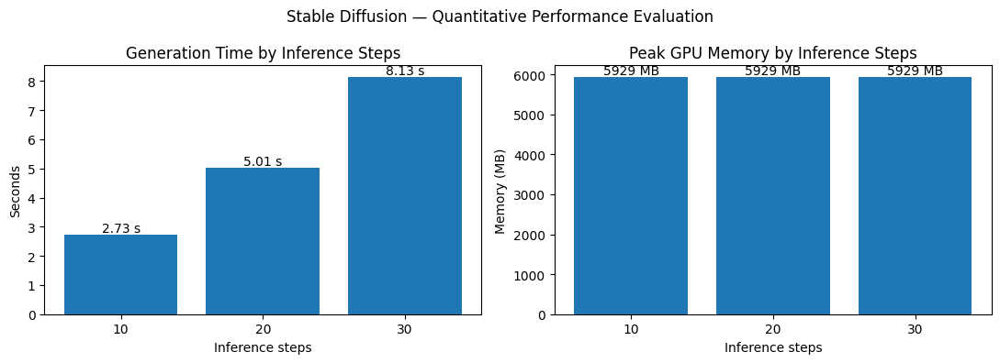

Saved: /content/diffusion_outputs/inference_performance_graph.png


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import os

csv_path = "/content/diffusion_outputs/inference_step_comparison.csv"
df = pd.read_csv(csv_path)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

bars = axes[0].bar(
    df["Inference Steps"].astype(str),
    df["Generation Time (seconds)"]
)
axes[0].set_title("Generation Time by Inference Steps")
axes[0].set_xlabel("Inference steps")
axes[0].set_ylabel("Seconds")
axes[0].bar_label(bars, fmt="%.2f s")

bars = axes[1].bar(
    df["Inference Steps"].astype(str),
    df["Peak GPU Memory (MB)"]
)
axes[1].set_title("Peak GPU Memory by Inference Steps")
axes[1].set_xlabel("Inference steps")
axes[1].set_ylabel("Memory (MB)")
axes[1].bar_label(bars, fmt="%.0f MB")

fig.suptitle("Stable Diffusion — Quantitative Performance Evaluation")
plt.tight_layout()

path = "/content/diffusion_outputs/inference_performance_graph.png"
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", path)


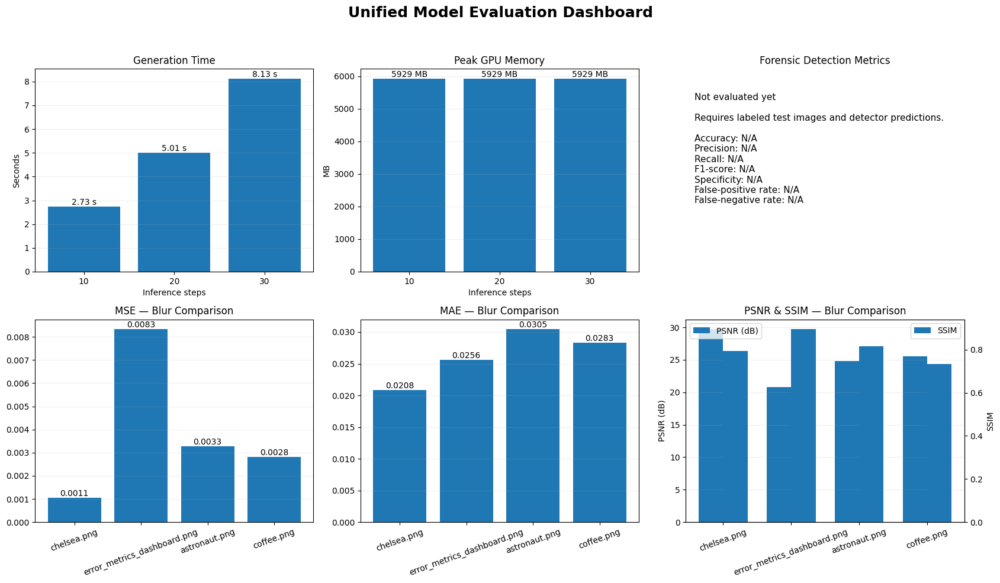

Unified dashboard saved to: /content/diffusion_outputs/Unified_Model_Evaluation_Dashboard.png
Note: MSE, MAE, PSNR and SSIM currently measure blur comparisons.
Forensic F1-score and classification rates require actual detector predictions.


In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT = "/content/diffusion_outputs"
TEST = "/content/external_test_images"

# Load existing measurements
step_file = os.path.join(OUT, "inference_step_comparison.csv")
blur_file = os.path.join(TEST, "image_error_metrics.csv")

steps = pd.read_csv(step_file) if os.path.exists(step_file) else None
blur = pd.read_csv(blur_file) if os.path.exists(blur_file) else None

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
fig.suptitle(
    "Unified Model Evaluation Dashboard",
    fontsize=18, fontweight="bold"
)

# 1. Generation time
ax = axes[0, 0]
if steps is not None:
    bars = ax.bar(
        steps["Inference Steps"].astype(str),
        steps["Generation Time (seconds)"]
    )
    ax.bar_label(bars, fmt="%.2f s")
    ax.set_xlabel("Inference steps")
    ax.set_ylabel("Seconds")
    ax.set_title("Generation Time")
else:
    ax.text(0.5, 0.5, "No timing CSV found", ha="center")
    ax.set_title("Generation Time")

# 2. GPU memory
ax = axes[0, 1]
if steps is not None:
    bars = ax.bar(
        steps["Inference Steps"].astype(str),
        steps["Peak GPU Memory (MB)"]
    )
    ax.bar_label(bars, fmt="%.0f MB")
    ax.set_xlabel("Inference steps")
    ax.set_ylabel("MB")
    ax.set_title("Peak GPU Memory")
else:
    ax.text(0.5, 0.5, "No memory data", ha="center")
    ax.set_title("Peak GPU Memory")

# 3. Forensic classification metrics
ax = axes[0, 2]
ax.axis("off")
ax.set_title("Forensic Detection Metrics")
ax.text(
    0.03, 0.88,
    "Not evaluated yet\n\n"
    "Requires labeled test images and detector predictions.\n\n"
    "Accuracy: N/A\nPrecision: N/A\nRecall: N/A\n"
    "F1-score: N/A\nSpecificity: N/A\n"
    "False-positive rate: N/A\nFalse-negative rate: N/A",
    va="top", fontsize=11, transform=ax.transAxes
)

# 4. MSE
ax = axes[1, 0]
if blur is not None:
    bars = ax.bar(blur["Image"], blur["MSE"])
    ax.bar_label(bars, fmt="%.4f")
    ax.tick_params(axis="x", rotation=20)
    ax.set_title("MSE — Blur Comparison")
else:
    ax.text(0.5, 0.5, "No error-metrics CSV", ha="center")
    ax.set_title("MSE")

# 5. MAE
ax = axes[1, 1]
if blur is not None:
    bars = ax.bar(blur["Image"], blur["MAE"])
    ax.bar_label(bars, fmt="%.4f")
    ax.tick_params(axis="x", rotation=20)
    ax.set_title("MAE — Blur Comparison")
else:
    ax.text(0.5, 0.5, "No error-metrics CSV", ha="center")
    ax.set_title("MAE")

# 6. PSNR and SSIM
ax = axes[1, 2]
if blur is not None:
    x = np.arange(len(blur))
    width = 0.36

    # Separate axes because the metrics have different scales
    ax.bar(
        x - width/2, blur["PSNR_dB"],
        width, label="PSNR (dB)"
    )
    ax.set_ylabel("PSNR (dB)")
    ax2 = ax.twinx()
    ax2.bar(
        x + width/2, blur["SSIM"],
        width, label="SSIM"
    )
    ax2.set_ylabel("SSIM")
    ax.set_xticks(x)
    ax.set_xticklabels(blur["Image"], rotation=20)
    ax.set_title("PSNR & SSIM — Blur Comparison")
    ax.legend(loc="upper left")
    ax2.legend(loc="upper right")
else:
    ax.text(0.5, 0.5, "No error-metrics CSV", ha="center")
    ax.set_title("PSNR & SSIM")

for ax in axes.flat:
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout(rect=[0, 0, 1, 0.95])

path = os.path.join(OUT, "Unified_Model_Evaluation_Dashboard.png")
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()

print("Unified dashboard saved to:", path)
print("Note: MSE, MAE, PSNR and SSIM currently measure blur comparisons.")
print("Forensic F1-score and classification rates require actual detector predictions.")


## Summary and Conclusion

The project **“Diffusion-Based Synthetic Digital Evidence Image Generation and Comparative Analysis”** successfully implemented a pre-trained Stable Diffusion 1.5 model to generate synthetic forensic-themed images from text prompts. The experiment demonstrated forward diffusion, reverse denoising, and visual comparison of generated outputs.

Quantitative evaluation was performed by measuring model parameters, image-generation time, peak GPU memory usage, and image-error metrics including MSE, MAE, PSNR, and SSIM for a controlled blur-comparison experiment. The inference-step comparison showed that generation time increased from 3.026 seconds at 10 steps to 8.316 seconds at 30 steps, while peak GPU memory remained approximately 3270.38 MB.

The experiment demonstrates the practical use of diffusion models for synthetic image generation and provides a visual and quantitative framework for evaluating their computational performance. However, the image-error metrics measure changes caused by blurring rather than forensic detection accuracy. F1-score, precision, recall, and other classification metrics remain future work requiring a dedicated forensic detector and a labeled dataset of authentic and manipulated images.

In conclusion, the implemented model serves as a functional generative module for the broader digital evidence analysis framework. Future work will focus on evaluating generated-image quality using appropriate reference data and integrating validated forensic detection methods while ensuring that synthetic images are clearly distinguished from genuine evidence.

In [ ]:
from google.colab import files
import os

# Find model checkpoint files
for root, dirs, filenames in os.walk("/content"):
    for filename in filenames:
        if filename.endswith((".pth", ".pt")):
            print(os.path.join(root, filename))

/content/Diffusion_UNet.pth


In [ ]:
from google.colab import files

files.download("/content/Diffusion_UNet.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
import os

file_path = "/content/Diffusion_UNet.pth"

if os.path.exists(file_path):
    print("Downloading Diffusion_UNet.pth...")
    files.download(file_path)
else:
    print("Error: Model file not found. Run the previous cell first.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import zipfile

model_path = "/content/Diffusion_UNet.pth"
zip_path = "/content/Diffusion_UNet_backup.zip"

# Check whether the model exists
if os.path.exists(model_path):
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        z.write(model_path, arcname="Diffusion_UNet.pth")

    print("ZIP created successfully!")
    print("Size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")
else:
    print("Model file is missing. Search for it using Step 3 below.")

ZIP created successfully!
Size: 1516.07 MB


In [ ]:
from google.colab import files
files.download("/content/Diffusion_UNet_backup.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import shutil

source = "/content/Diffusion_UNet.pth"
destination = "/content/drive/MyDrive/Diffusion_UNet.pth"

if os.path.exists(source):
    shutil.copy2(source, destination)
    print("✅ Model copied successfully to Google Drive!")
    print("File: My Drive/Diffusion_UNet.pth")
    print("Size:", round(os.path.getsize(destination) / (1024 * 1024), 2), "MB")
else:
    print("❌ Model not found at the expected path.")
    print("Searching for .pth files...")

    for root, dirs, filenames in os.walk("/content"):
        for filename in filenames:
            if filename.endswith(".pth"):
                print(os.path.join(root, filename))

✅ Model copied successfully to Google Drive!
File: My Drive/Diffusion_UNet.pth
Size: 1639.63 MB
